Данные были взяты из https://huggingface.co/datasets/papluca/language-identification

# Загрузка данных

1. Импорт библиотек

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

2. Определение констант

In [44]:
ROOT_DIR = Path.cwd().resolve()

if not (ROOT_DIR / "data").is_dir():
    ROOT_DIR = ROOT_DIR.parent

DATA_DIR = ROOT_DIR / "data"

3. Получение датафрейма

In [45]:
def load_data(path):
    df = pd.read_csv(path, dtype={"text":"string","labels":"string"})
    return df

splits = {
    name: load_data(DATA_DIR / f"{name}.csv") 
    for name in ("train", "valid", "test")
}

df = pd.concat(
    [part.assign(split=name) for name, part in splits.items()], 
    ignore_index=True,
  )

# Анализ

## Описание датасета

Выведем shape и info()

In [46]:
print(f"Dataset shape: {df.shape}")
print("Dataset info:")
df.info()

Dataset shape: (90000, 3)
Dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 90000 entries, 0 to 89999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   labels  90000 non-null  string
 1   text    90000 non-null  string
 2   split   90000 non-null  str   
dtypes: str(1), string(2)
memory usage: 2.1 MB


Загружено 90000 строк. В датафрейме 3 колонки (labels - правильный язык текста, например ru или en, text - текст, split - принадлежность к csv). Пропусков нет, отдельно нужно проверить пустые строки ("") и строки с пробелом(-ами).

In [47]:
display(
  df.loc[df["split"] == "train"]
  .sample(5, random_state=42)
)

,labels,text,split
46730,de,Hab für den Preis mehr erwartet.,train
48393,ru,"Письмо в письменном виде убийцы , друзья мои !",train
41416,hi,जापानियों ने रैंकिंग दृश ् य और स ् थानों के प...,train
34506,ar,"وفي عام 1853 , كان القصد من قصر دولما - bahce ...",train
43725,vi,"Các nhà chức trách y tế anh , trong 1995 nguyê...",train


Проверим количество языков и выведем списком

In [48]:
languages = sorted(df["labels"].unique())
print("Count of languages:", len(languages))
print("Languages codes:", ",".join(languages))

Count of languages: 20
Languages codes: ar,bg,de,el,en,es,fr,hi,it,ja,nl,pl,pt,ru,sw,th,tr,ur,vi,zh


В датасете собрано 20 языков. Далее посчитаем размеры выборок и их доли.


In [49]:
split_summary = (
  df["split"]
  .value_counts()
  .reindex(["train", "valid", "test"])
  .to_frame(name="count")
)

split_summary["percent"] = (split_summary["count"] / len(df) * 100).round(2)

display(split_summary)

,count,percent
split,,
train,70000,77.78
valid,10000,11.11
test,10000,11.11


Проверим распределение языков внутри каждой выборки

In [50]:
languages_counts = pd.crosstab(
  df["labels"],
  df["split"],
).reindex(columns=["train", "valid", "test"])

languages_counts["total"] = languages_counts.sum(axis=1)

display(languages_counts)

split,train,valid,test,total
labels,,,,
ar,3500,500,500,4500
bg,3500,500,500,4500
de,3500,500,500,4500
el,3500,500,500,4500
en,3500,500,500,4500
es,3500,500,500,4500
fr,3500,500,500,4500
hi,3500,500,500,4500
it,3500,500,500,4500


Визуализируем распределение языков

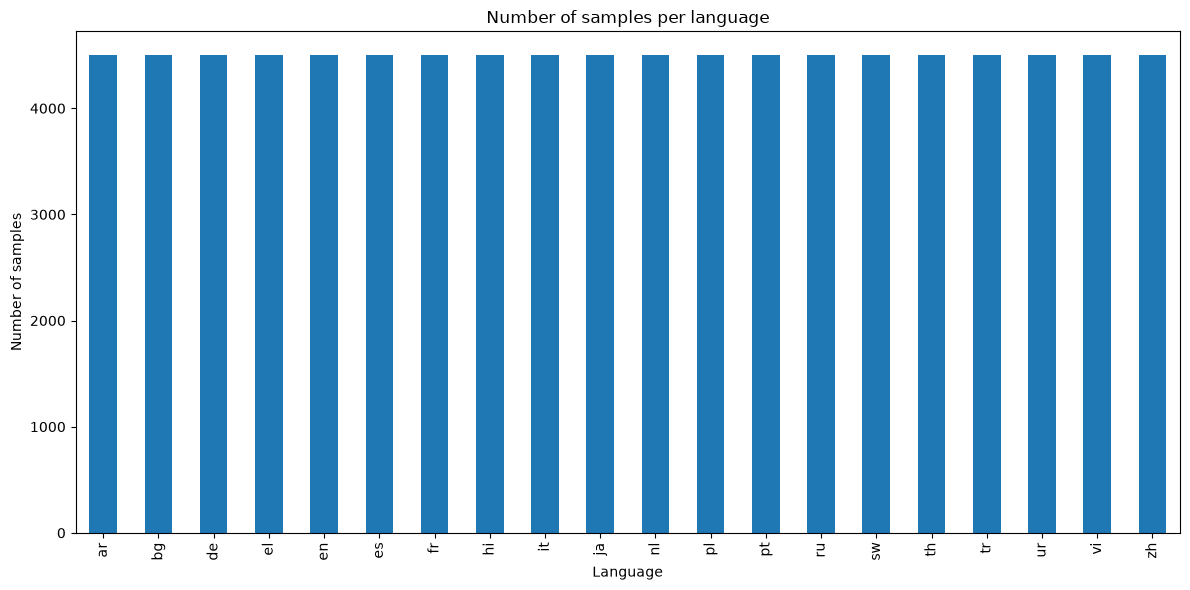

In [51]:
languages_counts["total"].plot(
  kind="bar",
  figsize=(12, 6),
  title="Number of samples per language",
)

plt.xlabel("Language")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.show()

### Вывод

Датасет содержит 90 000 примеров на 20 языках. Пропущенные значения отсутствуют. Каждый язык представлен 4 500 примерами: 3 500 в обучающей выборке, 500 в валидационной и 500 в тестовой. Классы сбалансированы внутри каждой выборки. Исходное разбиение составляет приблизительно 77,78/11,11/11,11% и отличается от предусмотренного в рабочей постановке 70/15/15. Качество текстов, дубликаты и пересечения выборок будут проверены отдельно.